In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

from src.data.load import load_data
from src.features.build import transform_features, build_preprocessor

RANDOM_STATE = 42
shap.initjs()

In [9]:
model = joblib.load(PROJECT_ROOT / "models" / "default_pipeline.pkl")

df = transform_features(load_data())
X = df.drop(columns=["default.payment.next.month"])
y = df["default.payment.next.month"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

feature_names = model.feature_name_

print(f"Модель:      {type(model).__name__}")
print(f"Признаков:   {X_test.shape[1]}")
print(f"Test ROC:    {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.4f}")

Модель:      LGBMClassifier
Признаков:   19
Test ROC:    0.7654


In [11]:
explainer = shap.TreeExplainer(model, X_test)
shap_vals = explainer.shap_values(X_test, check_additivity=False)

 98%|===================| 5892/6000 [00:51<00:00]        

In [14]:


mean_abs_shap = np.abs(shap_vals.mean(axis=0))
importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": mean_abs_shap,
}).sort_values("mean_abs_shap", ascending=False).head(20)

print(importance.to_string(index=False))
print(pd.DataFrame({"feature": feature_names, "imp": model.feature_importances_}).sort_values("imp", ascending=False).head(20))

      feature  mean_abs_shap
     PAY_AMT1       0.020022
LIMIT_BAL_log       0.016553
  UTILIZATION       0.016204
    BILL_mean       0.012594
     PAY_AMT3       0.011322
     BILL_std       0.010844
     MARRIAGE       0.005370
     PAY_AMT6       0.005268
     PAY_AMT5       0.003834
     PAY_AMT4       0.003793
      PAY_max       0.003776
          AGE       0.003666
          SEX       0.001987
     PAY_AMT2       0.001969
   BILL_trend       0.001840
    EDUCATION       0.001665
    has_delay       0.001268
    BILL_grow       0.000203
   never_paid       0.000048
          feature   imp
17    UTILIZATION  1343
13     BILL_trend  1233
11       BILL_std  1189
10      BILL_mean  1168
6        PAY_AMT3   911
4        PAY_AMT1   863
18  LIMIT_BAL_log   826
5        PAY_AMT2   809
7        PAY_AMT4   747
3             AGE   705
14        PAY_max   700
9        PAY_AMT6   681
8        PAY_AMT5   509
1       EDUCATION   382
2        MARRIAGE   196
0             SEX   150
15      has_

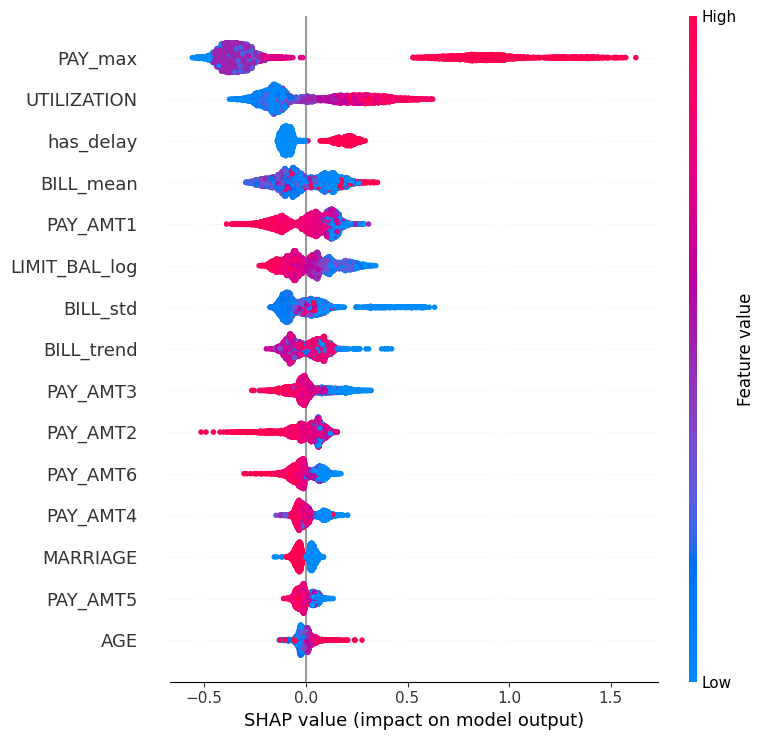

In [15]:
plt.figure(figsize=(10,8))
shap.summary_plot(shap_vals, X_test, feature_names=feature_names, max_display=15, show=False)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "summary_plot.png", dpi=150, bbox_inches='tight')
plt.show()

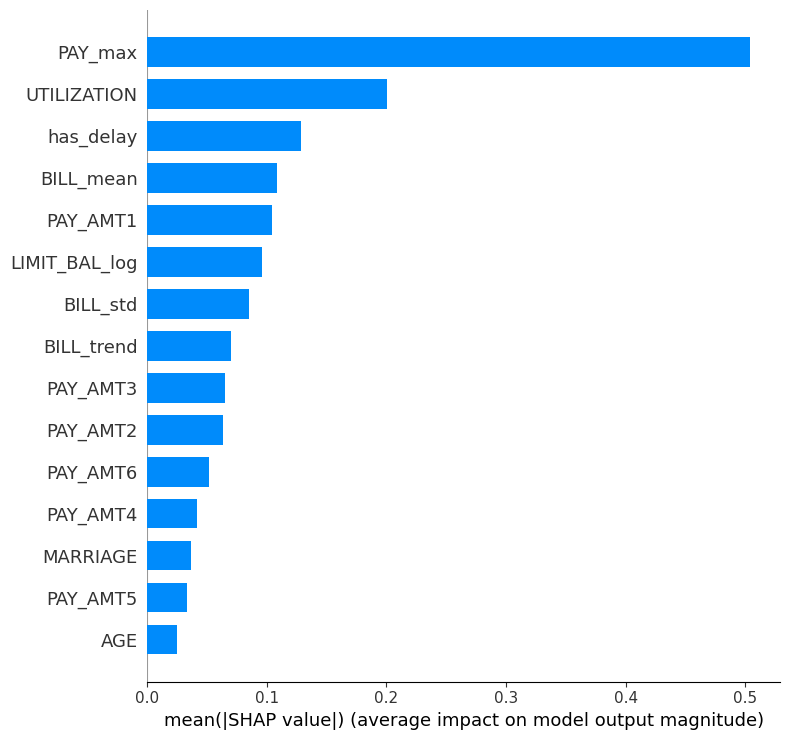

In [16]:
plt.figure(figsize=(9,6))
shap.summary_plot(shap_vals, X_test, feature_names=feature_names, max_display=15, show=False, plot_type='bar')
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "summary_plot_bar.png", dpi=150, bbox_inches='tight')
plt.show()

In [37]:
client_idx = 0
client = X_test.iloc[[client_idx]]
client_proba = model.predict_proba(client)[:, 1][0]

print(f"Клиент #{client_idx}")
print(f"default probability: {client_proba:.4f}")
print(f"Risk: {'high' if client_proba >= 0.43 else 'low'}")
print()
print(client.T)

Клиент #0
default probability: 0.2915
Risk: low

                      6907
SEX               1.000000
EDUCATION         2.000000
MARRIAGE          2.000000
AGE              46.000000
PAY_AMT1         10.168195
PAY_AMT2          0.000000
PAY_AMT3          8.152774
PAY_AMT4          7.749753
PAY_AMT5          7.475906
PAY_AMT6          7.952263
BILL_mean      6055.666667
BILL_std       9870.696058
BILL_grow         1.000000
BILL_trend     1224.000000
PAY_max           0.000000
has_delay         0.000000
never_paid        0.000000
UTILIZATION       0.121113
LIMIT_BAL_log    10.819798


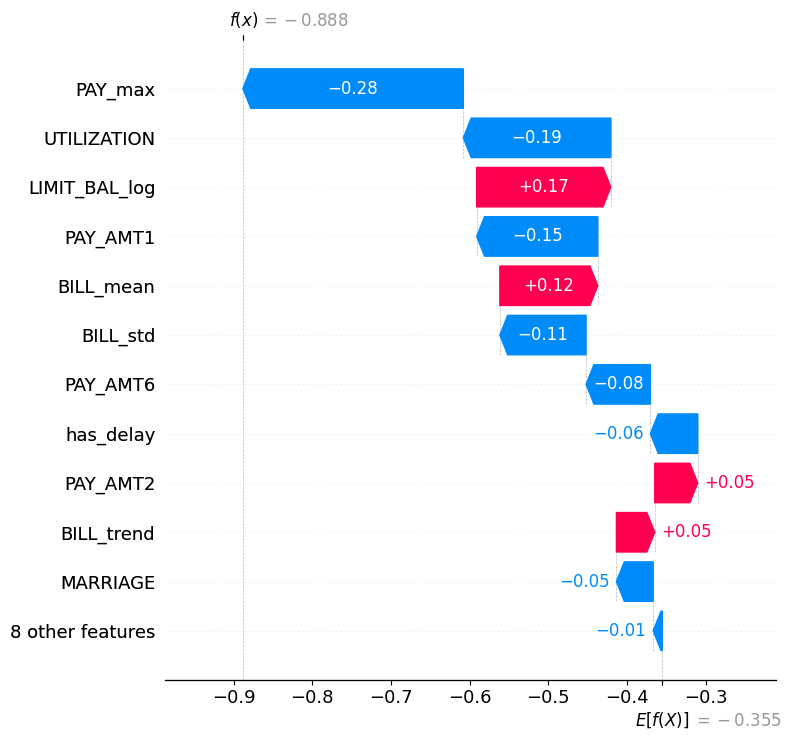

In [39]:
shap.plots._waterfall.waterfall_legacy(
    explainer.expected_value,
    shap_vals[client_idx],
    feature_names=feature_names,
    max_display=12,
    show=False
)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "waterfall_plot.png", dpi=150, bbox_inches='tight')
plt.show()